Loading Titanic Dataset...

--- Data Overview ---
Total Rows and Columns: (891, 15)

--- Missing Values in Dataset ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64 

--- Statistical Summary of Numerical Columns ---
         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.00000

/tmp/ipykernel_3635/4064803447.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='survived', palette='Set2')


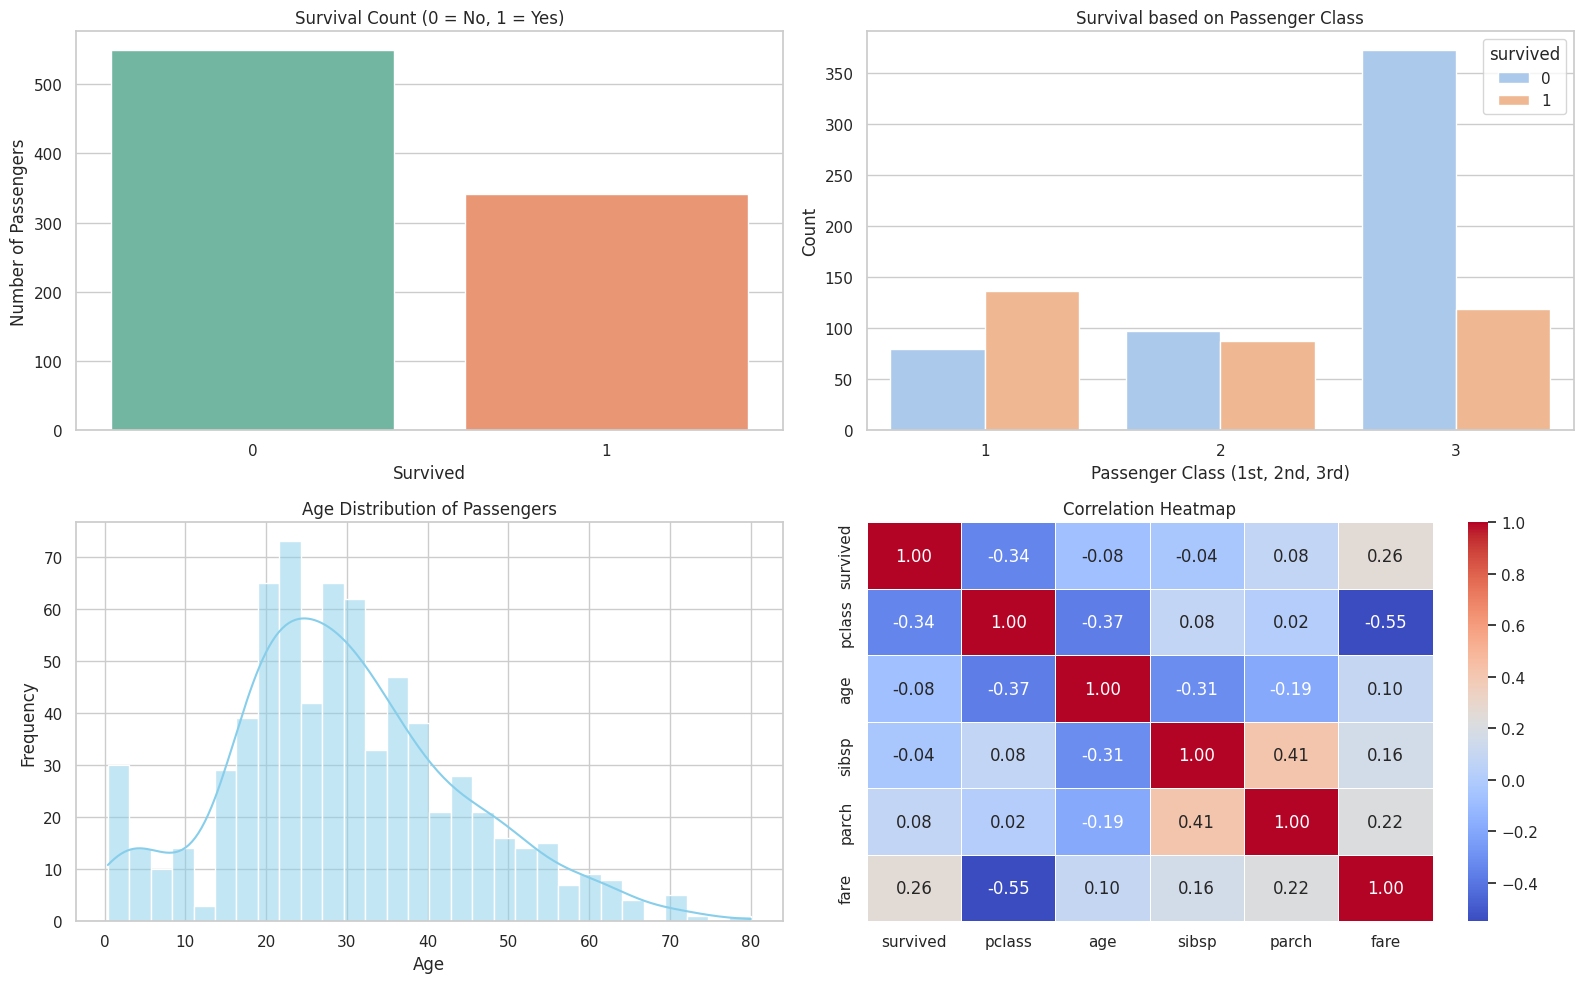


--- Key Insights ---
1. A large number of passengers did not survive.
2. Passengers in 1st Class had a higher survival rate compared to 3rd Class.
3. The majority of passengers were between the ages of 20 and 40.
4. There is a strong negative correlation between Pclass and Fare (1st class tickets cost more).


In [1]:
# Import required libraries for Data Analysis and Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (Using the built-in Titanic dataset from Seaborn)
print("Loading Titanic Dataset...\n")
df = sns.load_dataset('titanic')

# 2. Statistical Summaries and Data Overview
print("--- Data Overview ---")
print(f"Total Rows and Columns: {df.shape}\n")

print("--- Missing Values in Dataset ---")
print(df.isnull().sum(), "\n")

print("--- Statistical Summary of Numerical Columns ---")
print(df.describe(), "\n")

# 3. Data Visualization

# Set the visual style for the graphs
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

# Graph A: Survival Count (To see how many survived vs died)
plt.subplot(2, 2, 1)
sns.countplot(data=df, x='survived', palette='Set2')
plt.title('Survival Count (0 = No, 1 = Yes)')
plt.xlabel('Survived')
plt.ylabel('Number of Passengers')

# Graph B: Passenger Class vs Survival (Key Influencing Factor)
plt.subplot(2, 2, 2)
sns.countplot(data=df, x='pclass', hue='survived', palette='pastel')
plt.title('Survival based on Passenger Class')
plt.xlabel('Passenger Class (1st, 2nd, 3rd)')
plt.ylabel('Count')

# Graph C: Age Distribution
plt.subplot(2, 2, 3)
sns.histplot(df['age'].dropna(), kde=True, color='skyblue', bins=30)
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')

# Graph D: Correlation Heatmap (To identify relationships between numeric variables)
plt.subplot(2, 2, 4)
# Select only numeric columns for the correlation matrix to avoid errors
numeric_df = df.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

print("\n--- Key Insights ---")
print("1. A large number of passengers did not survive.")
print("2. Passengers in 1st Class had a higher survival rate compared to 3rd Class.")
print("3. The majority of passengers were between the ages of 20 and 40.")
print("4. There is a strong negative correlation between Pclass and Fare (1st class tickets cost more).")